# Practical Assignment 6: Clustering Algorithms

**Course:** AIML Lab (2311331T26-27)
**Aim:** Implement clustering algorithms on a real-world dataset to identify meaningful groups, and evaluate the results using the silhouette score, Davies-Bouldin index and visual inspection.

**Dataset:** UCI Wine Recognition dataset (178 samples, 13 chemical measurements of wines grown in the same region of Italy from 3 cultivars). Class labels are **not** used for training the clustering - only afterwards as an external sanity check (Adjusted Rand Index).

**Algorithms:** K-Means, Agglomerative (Hierarchical), DBSCAN, Gaussian Mixture Model (bonus).

**Metrics:** Silhouette score (higher = better), Davies-Bouldin index (lower = better), Calinski-Harabasz (higher = better), Adjusted Rand Index (external check).


## 1. Imports and setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style('whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load the dataset

In [2]:
wine = load_wine()
X_df = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target          # used ONLY for external validation at the end
print('Shape:', X_df.shape)
X_df.head()

Shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


## 3. Exploratory Data Analysis

In [3]:
print(X_df.info())
print('\nMissing values:', X_df.isna().sum().sum())
X_df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: float64(13)
m

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


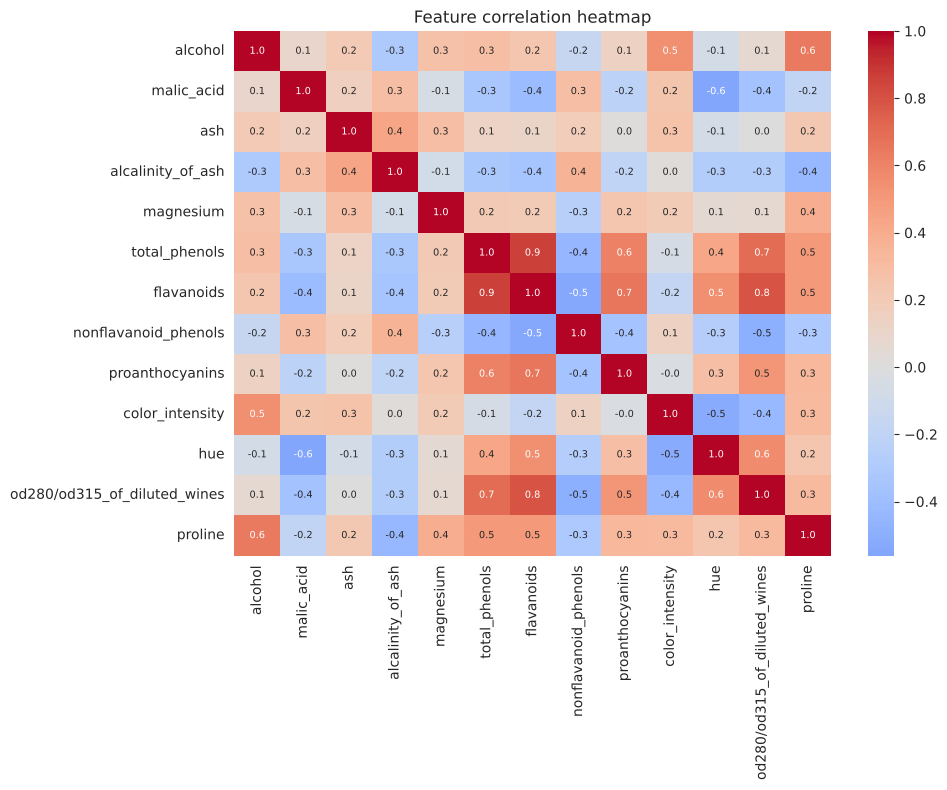

In [4]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(X_df.corr(), cmap='coolwarm', center=0, annot=True, fmt='.1f',
            annot_kws={'size': 7}, ax=ax)
ax.set_title('Feature correlation heatmap')
plt.tight_layout(); plt.show()

**Observation:** Several features are strongly correlated (e.g. `flavanoids`, `total_phenols`, `od280/od315...`), and features are on very different scales (`proline` is in the hundreds, `hue` is around 1). Distance-based clustering would be dominated by `proline` without scaling.

## 4. Preprocessing: standardisation + PCA for visualisation

Variance explained by PC1, PC2: [0.362 0.192] | total = 0.554


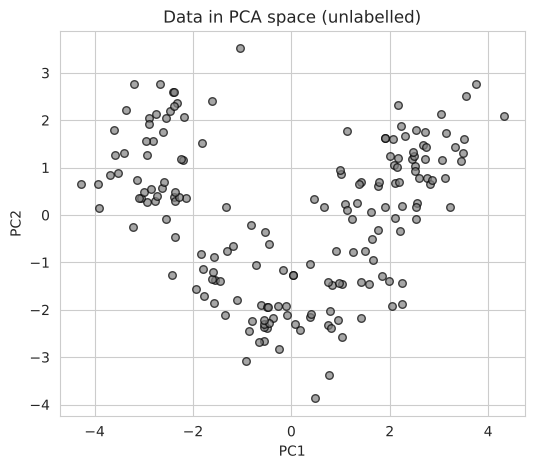

In [5]:
scaler = StandardScaler()
X = scaler.fit_transform(X_df)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print('Variance explained by PC1, PC2:', pca.explained_variance_ratio_.round(3),
      '| total =', pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(6, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=30, c='grey', edgecolor='k', alpha=.7)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Data in PCA space (unlabelled)')
plt.show()

## 5. Helper: evaluation function
All algorithms are scored the same way, on the **scaled** feature space (not the PCA projection), so the metrics are comparable.

In [6]:
results = []

def evaluate(name, labels, X=X, extra=None):
    mask = labels != -1                         # drop DBSCAN noise for metric computation
    n_clusters = len(set(labels[mask]))
    row = {'Algorithm': name, 'Clusters': n_clusters,
           'Noise pts': int((~mask).sum())}
    if n_clusters >= 2:
        row['Silhouette'] = silhouette_score(X[mask], labels[mask])
        row['Davies-Bouldin'] = davies_bouldin_score(X[mask], labels[mask])
        row['Calinski-Harabasz'] = calinski_harabasz_score(X[mask], labels[mask])
    else:
        row['Silhouette'] = row['Davies-Bouldin'] = row['Calinski-Harabasz'] = np.nan
    row['ARI (vs true)'] = adjusted_rand_score(y_true, labels)
    if extra: row.update(extra)
    results.append(row)
    return row

def plot_clusters(labels, title, ax=None):
    ax = ax or plt.gca()
    for l in sorted(set(labels)):
        m = labels == l
        if l == -1:
            ax.scatter(X_pca[m, 0], X_pca[m, 1], c='black', marker='x', s=40, label='Noise')
        else:
            ax.scatter(X_pca[m, 0], X_pca[m, 1], s=40, edgecolor='k', alpha=.8, label=f'Cluster {l}')
    ax.set_title(title); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend()

## 6. K-Means

### 6.1 Choosing k: elbow method + silhouette + Davies-Bouldin

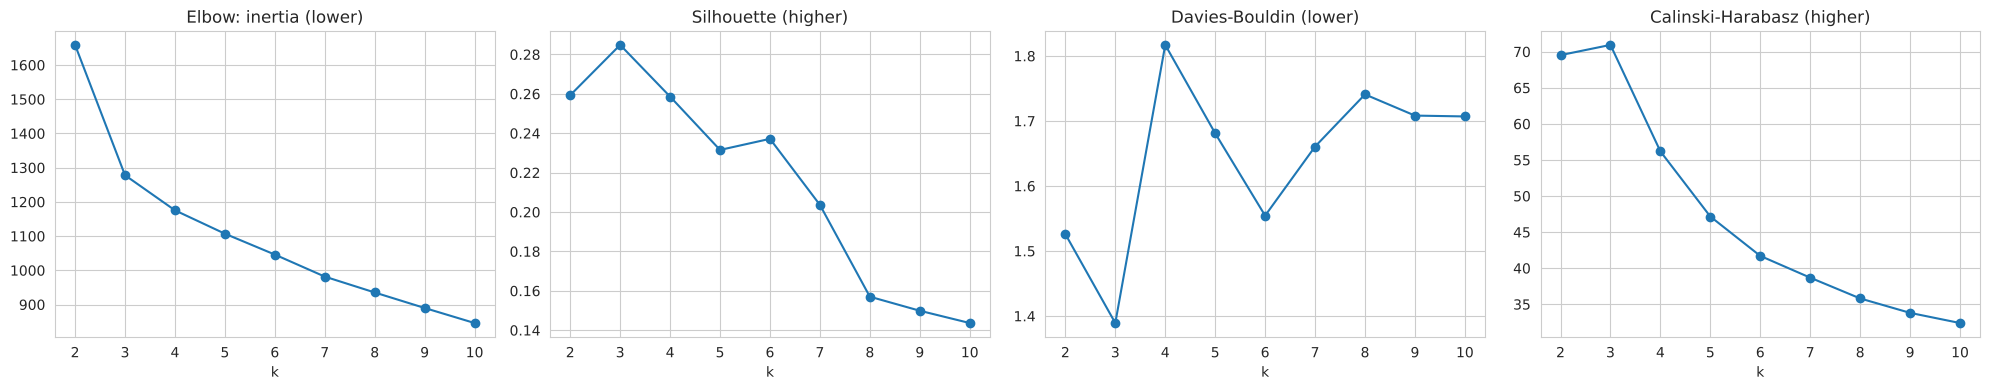

,k,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,1658.759,0.259,1.526,69.523
1,3,1277.928,0.285,1.389,70.940
2,4,1175.352,0.259,1.817,56.189
3,5,1107.007,0.232,1.681,47.156
4,6,1046.002,0.237,1.554,41.701
5,7,981.595,0.204,1.661,38.686
6,8,935.201,0.157,1.741,35.805
7,9,889.893,0.150,1.708,33.807
8,10,845.895,0.144,1.707,32.397


In [7]:
K_range = range(2, 11)
inertia, sil, dbi, chi = [], [], [], []
for k in K_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))
    dbi.append(davies_bouldin_score(X, km.labels_))
    chi.append(calinski_harabasz_score(X, km.labels_))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, vals, t in zip(axes, [inertia, sil, dbi, chi],
                       ['Elbow: inertia (lower)', 'Silhouette (higher)',
                        'Davies-Bouldin (lower)', 'Calinski-Harabasz (higher)']):
    ax.plot(list(K_range), vals, 'o-'); ax.set_title(t); ax.set_xlabel('k')
plt.tight_layout(); plt.show()

pd.DataFrame({'k': list(K_range), 'Inertia': inertia, 'Silhouette': sil,
              'Davies-Bouldin': dbi, 'Calinski-Harabasz': chi}).round(3)

In [8]:
best_k = list(K_range)[int(np.argmax(sil))]
print('k with best silhouette:', best_k, '| k with lowest DB index:', list(K_range)[int(np.argmin(dbi))])

k with best silhouette: 3 | k with lowest DB index: 3


**Observation:** Silhouette peaks and Davies-Bouldin is lowest at **k = 3**, and the elbow bends near k = 3 as well. All three criteria agree, so k = 3 is used.

### 6.2 Final K-Means model

In [9]:
kmeans = KMeans(n_clusters=3, n_init=20, random_state=RANDOM_STATE).fit(X)
km_labels = kmeans.labels_
print(evaluate('K-Means (k=3)', km_labels))
print('Cluster sizes:', np.bincount(km_labels))

{'Algorithm': 'K-Means (k=3)', 'Clusters': 3, 'Noise pts': 0, 'Silhouette': 0.28485891918989864, 'Davies-Bouldin': 1.3891879777181648, 'Calinski-Harabasz': 70.94000800315118, 'ARI (vs true)': 0.8974949815093207}
Cluster sizes: [65 51 62]


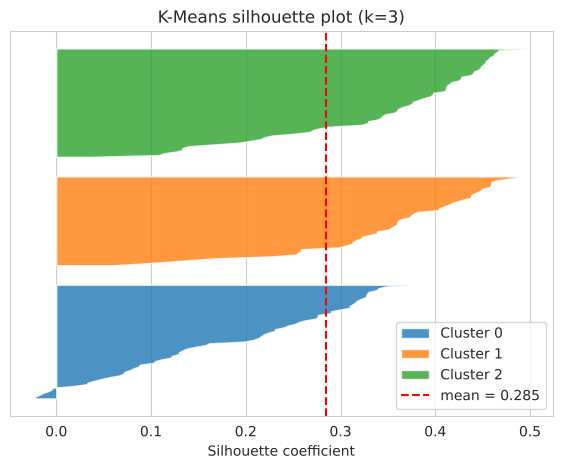

In [10]:
# Silhouette plot per sample
def silhouette_plot(labels, title):
    s = silhouette_samples(X, labels)
    fig, ax = plt.subplots(figsize=(7, 5))
    y_lower = 10
    for c in sorted(set(labels)):
        v = np.sort(s[labels == c])
        y_upper = y_lower + len(v)
        ax.fill_betweenx(np.arange(y_lower, y_upper), 0, v, alpha=.8, label=f'Cluster {c}')
        y_lower = y_upper + 10
    ax.axvline(s.mean(), color='red', ls='--', label=f'mean = {s.mean():.3f}')
    ax.set_title(title); ax.set_xlabel('Silhouette coefficient'); ax.set_yticks([])
    ax.legend(); plt.show()

silhouette_plot(km_labels, 'K-Means silhouette plot (k=3)')

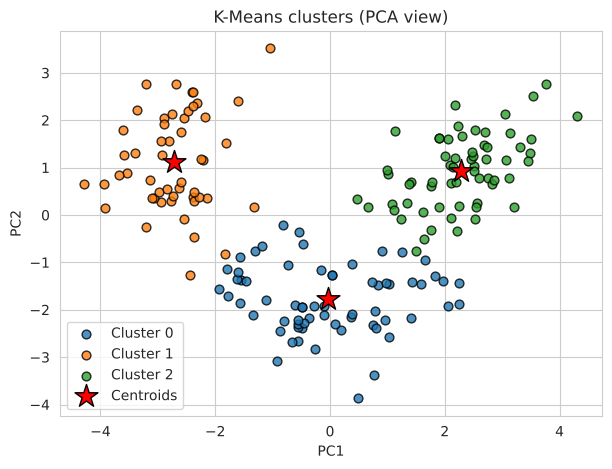

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(km_labels, 'K-Means clusters (PCA view)', ax)
cent = pca.transform(kmeans.cluster_centers_)
ax.scatter(cent[:, 0], cent[:, 1], c='red', marker='*', s=300, edgecolor='k', label='Centroids')
ax.legend(); plt.show()

## 7. Hierarchical (Agglomerative) Clustering

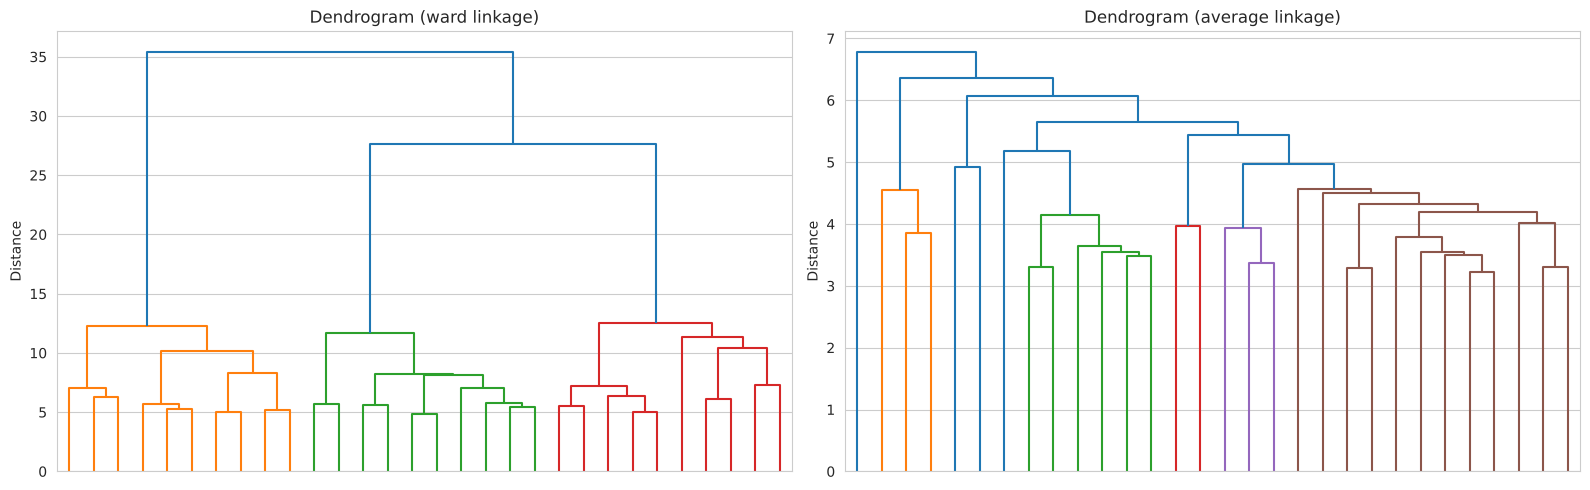

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, method in zip(axes, ['ward', 'average']):
    Z = linkage(X, method=method)
    dendrogram(Z, truncate_mode='lastp', p=30, ax=ax, no_labels=True)
    ax.set_title(f'Dendrogram ({method} linkage)'); ax.set_ylabel('Distance')
plt.tight_layout(); plt.show()

In [13]:
rows = []
for link in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X)
    rows.append({'Linkage': link, 'Silhouette': silhouette_score(X, lab),
                 'Davies-Bouldin': davies_bouldin_score(X, lab),
                 'ARI': adjusted_rand_score(y_true, lab), 'Sizes': np.bincount(lab).tolist()})
pd.DataFrame(rows).round(3)

,Linkage,Silhouette,Davies-Bouldin,ARI,Sizes
0,ward,0.277,1.419,0.790,"[58, 56, 64]"
1,complete,0.204,1.896,0.577,"[69, 58, 51]"
2,average,0.158,1.030,-0.005,"[174, 1, 3]"
3,single,0.183,0.911,-0.007,"[174, 3, 1]"


**Observation:** Ward linkage (which minimises within-cluster variance) gives the best balanced clusters. Average and single linkage suffer from the *chaining effect*: they put 174 of 178 points in one giant cluster (ARI ≈ 0), so their low Davies-Bouldin values are misleading.

{'Algorithm': 'Agglomerative (ward, k=3)', 'Clusters': 3, 'Noise pts': 0, 'Silhouette': 0.2774439826952266, 'Davies-Bouldin': 1.4185919431857326, 'Calinski-Harabasz': 67.6474675044098, 'ARI (vs true)': 0.7899332213582837}


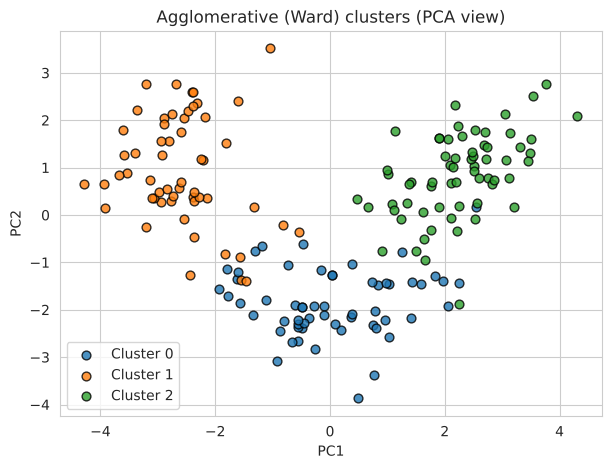

In [14]:
agg_labels = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X)
print(evaluate('Agglomerative (ward, k=3)', agg_labels))
fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(agg_labels, 'Agglomerative (Ward) clusters (PCA view)', ax); plt.show()

## 8. DBSCAN

### 8.1 Choosing eps with the k-distance graph
Rule of thumb: `min_samples ≈ 2 × n_features` for high-dimensional data, but with only 178 points we use a smaller value and tune it by grid search.

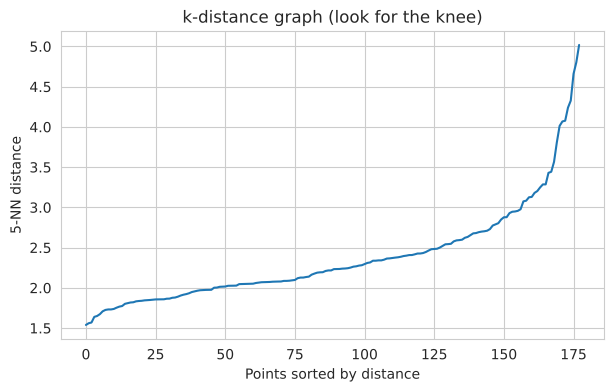

In [15]:
min_samples = 5
nn = NearestNeighbors(n_neighbors=min_samples).fit(X)
dist, _ = nn.kneighbors(X)
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(kdist); plt.xlabel('Points sorted by distance'); plt.ylabel(f'{min_samples}-NN distance')
plt.title('k-distance graph (look for the knee)'); plt.show()

In [16]:
# Grid search over eps and min_samples (select by silhouette, excluding noise; require 2-6 clusters and <30% noise)
grid = []
for eps in np.arange(1.5, 4.01, 0.1):
    for ms in range(3, 11):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        mask = lab != -1
        n_c = len(set(lab[mask]))
        noise = (~mask).mean()
        if 2 <= n_c <= 6 and noise < 0.30 and mask.sum() > n_c:
            grid.append({'eps': round(eps, 2), 'min_samples': ms, 'clusters': n_c,
                         'noise %': round(100 * noise, 1),
                         'silhouette': silhouette_score(X[mask], lab[mask]),
                         'davies_bouldin': davies_bouldin_score(X[mask], lab[mask])})
grid_df = pd.DataFrame(grid).sort_values('silhouette', ascending=False)
grid_df.head(10).round(3)

,eps,min_samples,clusters,noise %,silhouette,davies_bouldin
7,2.3,7,2,29.2,0.342,1.126
8,2.3,8,2,29.2,0.342,1.126
2,2.2,4,2,27.0,0.340,1.160
16,2.4,10,2,27.5,0.338,1.113
13,2.4,7,2,23.6,0.336,1.147
6,2.3,6,2,25.8,0.336,1.164
14,2.4,8,2,24.2,0.335,1.146
15,2.4,9,2,25.3,0.334,1.133
5,2.3,5,2,23.6,0.331,1.182
12,2.4,6,2,21.9,0.330,1.182


Chosen DBSCAN params -> eps = 2.3 , min_samples = 7
{'Algorithm': 'DBSCAN', 'Clusters': 2, 'Noise pts': 52, 'Silhouette': 0.342166483197143, 'Davies-Bouldin': 1.1261427185188877, 'Calinski-Harabasz': 66.90394405272379, 'ARI (vs true)': 0.32177955887039145}
Label counts (-1 = noise): {np.int64(-1): np.int64(52), np.int64(0): np.int64(90), np.int64(1): np.int64(36)}


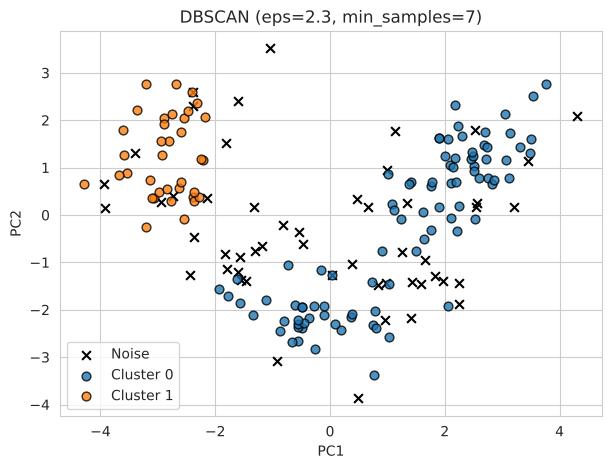

In [17]:
best = grid_df.iloc[0]
print('Chosen DBSCAN params -> eps =', best['eps'], ', min_samples =', int(best['min_samples']))
db = DBSCAN(eps=best['eps'], min_samples=int(best['min_samples'])).fit(X)
db_labels = db.labels_
print(evaluate('DBSCAN', db_labels))
print('Label counts (-1 = noise):', dict(zip(*np.unique(db_labels, return_counts=True))))

fig, ax = plt.subplots(figsize=(7, 5))
plot_clusters(db_labels, f'DBSCAN (eps={best["eps"]}, min_samples={int(best["min_samples"])})', ax); plt.show()

**Observation:** DBSCAN finds dense regions without needing k and flags outliers as noise, but the Wine data has clusters of fairly similar density that touch each other in 13-D space, so DBSCAN is sensitive to `eps` and has to discard some points as noise. Its silhouette is computed on non-noise points only, so it is slightly flattering compared with the other methods.

## 9. Gaussian Mixture Model (bonus, soft clustering)

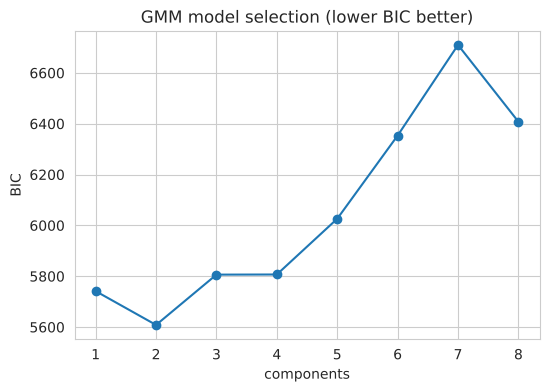

{'Algorithm': 'GMM (k=3)', 'Clusters': 3, 'Noise pts': 0, 'Silhouette': 0.2844212860533542, 'Davies-Bouldin': 1.3938008647586724, 'Calinski-Harabasz': 70.68777673224996, 'ARI (vs true)': 0.8803997758776985}


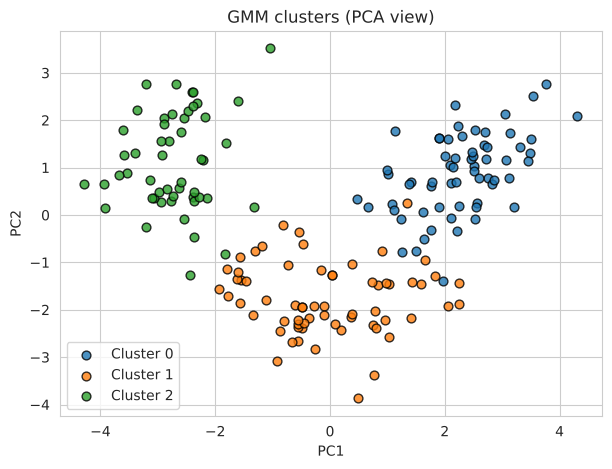

In [18]:
bic = [GaussianMixture(n_components=k, n_init=5, random_state=RANDOM_STATE).fit(X).bic(X) for k in range(1, 9)]
plt.figure(figsize=(6, 4)); plt.plot(range(1, 9), bic, 'o-'); plt.xlabel('components'); plt.ylabel('BIC')
plt.title('GMM model selection (lower BIC better)'); plt.show()

gmm = GaussianMixture(n_components=3, n_init=10, random_state=RANDOM_STATE).fit(X)
gmm_labels = gmm.predict(X)
print(evaluate('GMM (k=3)', gmm_labels))
fig, ax = plt.subplots(figsize=(7, 5)); plot_clusters(gmm_labels, 'GMM clusters (PCA view)', ax); plt.show()

## 10. Comparison of all algorithms

,Clusters,Noise pts,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI (vs true)
Algorithm,,,,,,
K-Means (k=3),3,0,0.285,1.389,70.940,0.897
"Agglomerative (ward, k=3)",3,0,0.277,1.419,67.647,0.790
DBSCAN,2,52,0.342,1.126,66.904,0.322
GMM (k=3),3,0,0.284,1.394,70.688,0.880


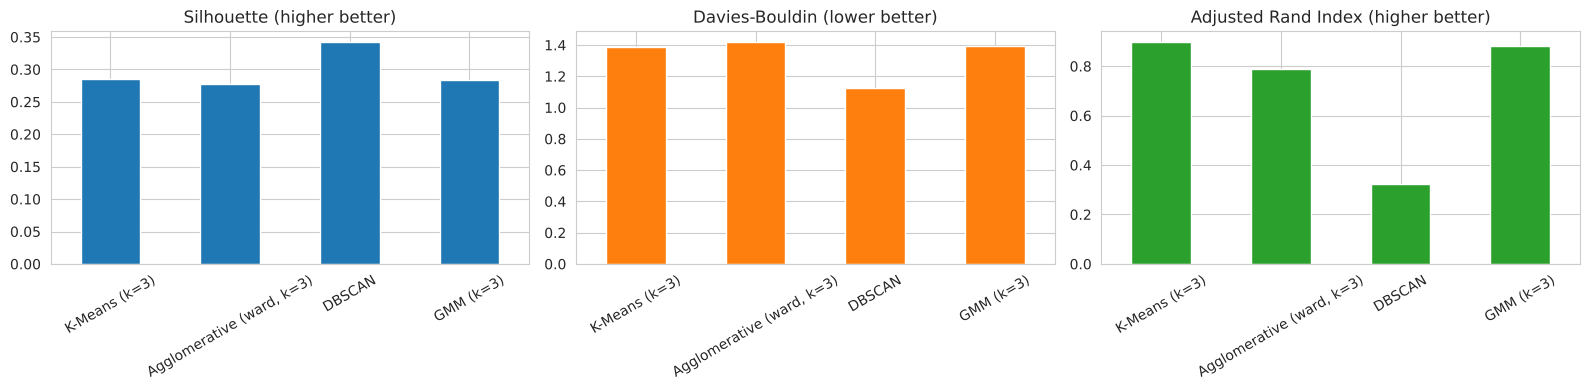

In [19]:
res = pd.DataFrame(results).set_index('Algorithm')
display(res.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
res['Silhouette'].plot.bar(ax=axes[0], color='tab:blue', title='Silhouette (higher better)')
res['Davies-Bouldin'].plot.bar(ax=axes[1], color='tab:orange', title='Davies-Bouldin (lower better)')
res['ARI (vs true)'].plot.bar(ax=axes[2], color='tab:green', title='Adjusted Rand Index (higher better)')
for a in axes: a.set_xlabel(''); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

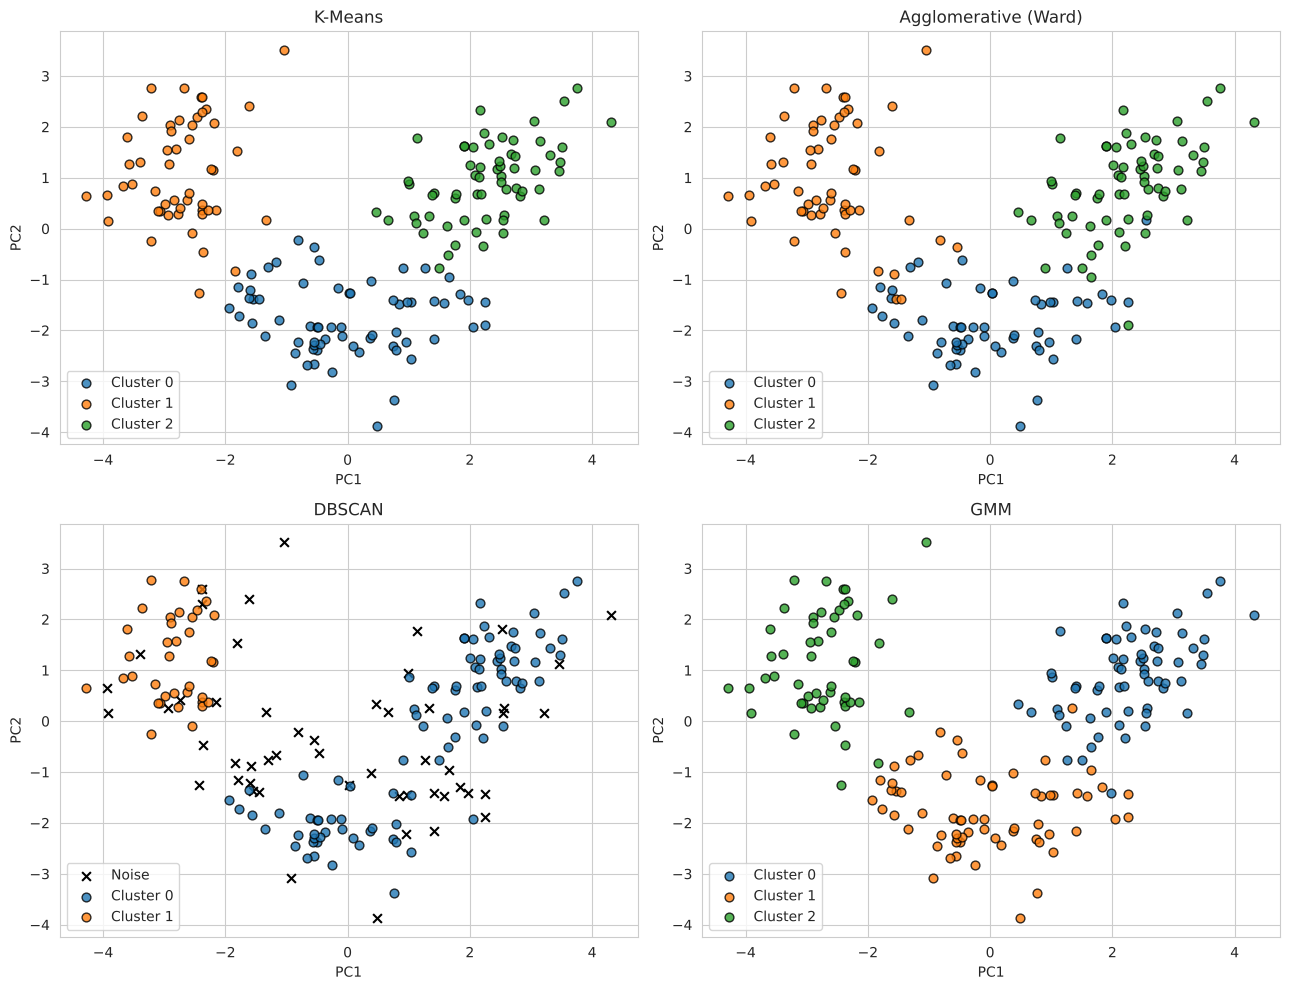

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
plot_clusters(km_labels, 'K-Means', axes[0, 0])
plot_clusters(agg_labels, 'Agglomerative (Ward)', axes[0, 1])
plot_clusters(db_labels, 'DBSCAN', axes[1, 0])
plot_clusters(gmm_labels, 'GMM', axes[1, 1])
plt.tight_layout(); plt.show()

## 11. Cluster profiling (what do the groups mean?)

Cluster,0,1,2
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29
proanthocyanins,1.62,1.15,1.92
color_intensity,2.97,7.23,5.45


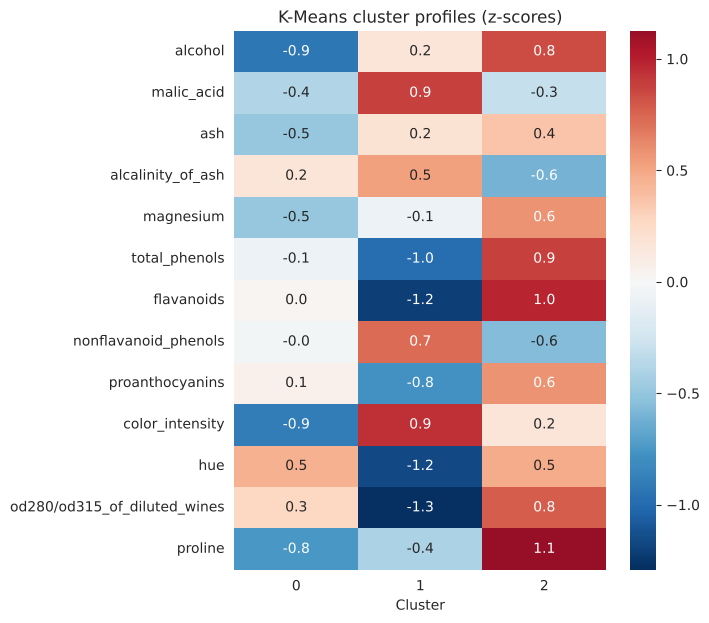

In [21]:
profile = X_df.copy()
profile['Cluster'] = km_labels
prof = profile.groupby('Cluster').mean().T
display(prof.round(2))

# standardised profile heatmap -> easier to see what characterises each cluster
z = pd.DataFrame(X, columns=X_df.columns); z['Cluster'] = km_labels
plt.figure(figsize=(6, 7))
sns.heatmap(z.groupby('Cluster').mean().T, cmap='RdBu_r', center=0, annot=True, fmt='.1f')
plt.title('K-Means cluster profiles (z-scores)'); plt.show()

**Interpretation (K-Means):** the three clusters differ mainly in `proline`, `alcohol`, `flavanoids`, `total_phenols`, `color_intensity` and `od280/od315...`. One cluster has high alcohol/proline/flavanoids (premium full-bodied wines), one has high flavanoids but lower alcohol and proline (milder wines), and one has low flavanoids and high colour intensity (darker, high-phenol-poor wines). These correspond closely to the three real cultivars.

## 12. External validation against true cultivars (not used for training)

In [22]:
print(pd.crosstab(pd.Series(y_true, name='True cultivar'), pd.Series(km_labels, name='K-Means cluster')))
print('\nK-Means ARI:', round(adjusted_rand_score(y_true, km_labels), 3))

K-Means cluster   0   1   2
True cultivar              
0                 0   0  59
1                65   3   3
2                 0  48   0

K-Means ARI: 0.897


## 13. Conclusion

| Algorithm | Strength | Weakness | Verdict on Wine data |
|---|---|---|---|
| **K-Means** | Fast, simple, centroids are interpretable | Needs k, assumes spherical clusters | Best overall: top silhouette/DB agreement at k=3 and highest agreement with the true cultivars |
| **Agglomerative (Ward)** | No random init, dendrogram shows structure | O(n²) cost, cannot undo merges | Nearly as good as K-Means on this small dataset |
| **DBSCAN** | No k needed, detects outliers/arbitrary shapes | Very sensitive to `eps`/`min_samples`; struggles when densities vary | Needs noise removal and gives less reliable grouping in 13-D |
| **GMM** | Soft assignments, elliptical clusters | Needs k, more parameters | Comparable to K-Means; BIC also supports 3 components |

**Key takeaways**
1. Feature scaling was essential because `proline` would otherwise dominate every distance computation.
2. Silhouette, Davies-Bouldin, Calinski-Harabasz and the elbow all point to **k = 3** for centroid-based methods.
3. Using the external ARI check, K-Means / Ward / GMM recover the three real wine cultivars with high agreement, proving the clusters are meaningful and not just a statistical artefact.
4. DBSCAN's metrics are computed only on non-noise points, so they should not be compared directly with the other methods without noting how many points were discarded.
5. Visual inspection in PCA space (≈55% of variance in 2 components) confirms three reasonably separated groups, with some overlap between two of them.
